## 1. The task

Every graph in FRANKENSTEIN is one molecule. The nodes are atoms and the edges are chemical bonds. The molecules come from a mutagenicity dataset, but each atom's chemical symbol was replaced by the pixel intensities of an MNIST digit image, a 780-dimensional vector. So the model cannot read the atom type directly; it has to recognise it from a noisy picture.

For a molecule $G=(V,E,X)$ we predict one label $y\in\{0,1\}$ for the whole graph, mutagenic or non-mutagenic. This is graph classification.

The model is a Graph Convolutional Network (GCN). We look at the data, train a plain GCN, tune it on the validation split, and finish with three short analyses of the tuned model.

Kaggle already has PyTorch, so we only install PyTorch Geometric.

In [1]:
!pip install -q torch_geometric

## 2. Set the experiment budget

All the settings that control run time are here.

A training run lasts at most `epochs` epochs and stops early once validation accuracy has not improved for `patience` epochs. Every run uses mini-batches of `batch_size` graphs.

The search tries `n_trials` random configurations, each with every seed in `search_seeds`. The winner is retrained on ten fresh seeds, `final_seeds`, that were never used for selection. The analyses use the first five of them, `abl_seeds`.

In [2]:
import time
t0 = time.time()
epochs, patience, batch_size = 200, 30, 64
n_trials, search_seeds = 20, [0, 1, 2]
final_seeds = list(range(100, 110))
abl_seeds = final_seeds[:5]

## 3. Load FRANKENSTEIN

FRANKENSTEIN is one of the TU Dortmund benchmark datasets, and PyG downloads it with `TUDataset`.

Its node features are continuous attributes, not discrete labels, and `TUDataset` drops continuous attributes unless we pass `use_node_attr=True`. Without it every node would get an empty feature vector.

The data goes to `/tmp` so that Kaggle does not copy the raw files into the notebook output. PyG warns on every max-pooling call that an optional package would make it faster; we silence just that message.

In [3]:
import torch
import warnings
from torch_geometric.datasets import TUDataset
warnings.filterwarnings('ignore', message='.*can be accelerated via')

dataset = TUDataset('/tmp/tud', 'FRANKENSTEIN', use_node_attr=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("graphs =", len(dataset), "   classes =", dataset.num_classes)
print("node features =", dataset.num_features, "   device =", device)

Processing...


graphs = 4337    classes = 2
node features = 780    device = cuda


Done!


## 4. One molecule

A graph is stored as node features `x` of shape $|V|\times780$, an edge list `edge_index` of shape $2\times|E|$, and a label `y`.

In [4]:
g = dataset[0]
print(g)
print("first edges:", g.edge_index[:, :8].tolist())
print("label:", g.y.item())

Data(edge_index=[2, 56], x=[25, 780], y=[1])
first edges: [[0, 0, 0, 1, 1, 1, 2, 2], [1, 2, 3, 0, 4, 5, 0, 6]]
label: 1


## 5. Check the graphs and the features

A GCN needs every bond stored in both directions, otherwise messages flow only one way. We check that, count graphs with isolated atoms, and look at the range of the features.

In [5]:
graphs = list(dataset)
X = torch.cat([g.x for g in graphs])
print("undirected graphs:", sum(g.is_undirected() for g in graphs), "of", len(graphs))
print("graphs with an isolated atom:", sum(g.has_isolated_nodes() for g in graphs))
print("feature range:", round(X.min().item(), 3), "to", round(X.max().item(), 3))
print("share of zero entries:", round((X == 0).float().mean().item(), 3))

undirected graphs: 4337 of 4337
graphs with an isolated atom: 209
feature range: 0.0 to 1.0
share of zero entries: 0.858


## 6. Split into train, validation and test

Unlike UPFD, FRANKENSTEIN has no official split. We make a stratified 80/10/10 split with a fixed random state, so both classes keep their share in every part and the other models can rebuild exactly the same split. The indices are also saved with the results.

The validation split chooses hyperparameters and the stopping epoch. The test split is used only to report results.

In [6]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

y = np.array([g.y.item() for g in graphs])
train_idx, rest = train_test_split(np.arange(len(y)), train_size=0.8, stratify=y, random_state=0)
val_idx, test_idx = train_test_split(rest, train_size=0.5, stratify=y[rest], random_state=0)

train_set, val_set, test_set = [[graphs[i] for i in idx] for idx in [train_idx, val_idx, test_idx]]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
for s, yy in zip(['train', 'val', 'test'], [y_train, y_val, y_test]):
    print(s, "  graphs =", len(yy), "  class 0 =", (yy == 0).sum(), "  class 1 =", (yy == 1).sum())

train   graphs = 3469   class 0 = 1549   class 1 = 1920
val   graphs = 434   class 0 = 193   class 1 = 241
test   graphs = 434   class 0 = 194   class 1 = 240


## 7. Class balance and molecule size

If both classes are about equally frequent, accuracy is a fair primary metric. We still report macro-F1 and ROC-AUC next to it.

In [7]:
counts = pd.DataFrame(dict(y=y, nodes=[g.num_nodes for g in graphs], edges=[g.num_edges // 2 for g in graphs]))
print(counts.groupby('y')[['nodes', 'edges']].describe().round(1).T)

y                 0       1
nodes count  1936.0  2401.0
      mean     16.4    17.3
      std      11.1     9.9
      min       2.0     2.0
      25%      10.0    12.0
      50%      14.0    17.0
      75%      20.0    21.0
      max     214.0   197.0
edges count  1936.0  2401.0
      mean     16.9    18.6
      std      12.2    11.1
      min       1.0     1.0
      25%       9.0    12.0
      50%      14.0    18.0
      75%      22.0    23.0
      max     217.0   206.0


## 8. How far does size alone go?

Two reference points for every GCN number below:

- always predicting the larger class, which needs no input at all;
- a logistic regression on $\log|V|$, the number of atoms, fitted on the training graphs. It tells us how much of the label is explained by size alone.

In [8]:
from sklearn.linear_model import LogisticRegression
logn = lambda d: np.log([[g.num_nodes] for g in d])
size_acc = LogisticRegression().fit(logn(train_set), y_train).score(logn(test_set), y_test)
print("test accuracy, always the larger class:", round(max(np.mean(y_test == 0), np.mean(y_test == 1)), 4))
print("test accuracy from log|V| alone:      ", round(size_acc, 4))

test accuracy, always the larger class: 0.553
test accuracy from log|V| alone:       0.576


## 9. The GCN layer

One GCN layer updates every node from itself and its neighbours:

$H^{(l+1)}=\sigma\left(\tilde D^{-1/2}\tilde A\tilde D^{-1/2}H^{(l)}W^{(l)}\right)$

where $\tilde A=A+I$ adds a self-loop to each node and $\tilde D_{ii}=\sum_j\tilde A_{ij}$ is its degree.

For one node this reads $h_i'=\sigma\Big(\sum_{j\in N(i)\cup\{i\}}\frac{1}{\sqrt{\tilde d_i\tilde d_j}}\,W h_j\Big)$, a degree-weighted average over the atom and its bonded neighbours.

A single layer maps every atom's 780 features to a new width.

In [9]:
from torch_geometric.nn import GCNConv
conv = GCNConv(dataset.num_features, 16)
print("one layer:", tuple(g.x.shape), "->", tuple(conv(g.x, g.edge_index).shape))

one layer: (25, 780) -> (25, 16)


## 10. From atoms to one graph vector

After $L$ layers each atom has seen its $L$-hop neighbourhood. PyG's `GCN` stacks $L$ such layers with ReLU, dropout and, if `bn=True`, batch norm in between.

A readout then pools the atom embeddings into one vector per molecule, $h_G=\text{READOUT}\{h_v^{(L)}:v\in V\}$, with the mean, the max or the sum. An MLP maps $h_G$ to two logits, one per class.

`embed` returns $h_G$; we use it later for the t-SNE plot. Training settings stored in the same dictionary, such as the learning rate, are ignored by the model.

In [10]:
import torch.nn.functional as F
from torch_geometric.nn import GCN, MLP, global_mean_pool, global_max_pool, global_add_pool

pools = dict(mean=global_mean_pool, max=global_max_pool, add=global_add_pool)

class Net(torch.nn.Module):
    def __init__(self, hidden=64, layers=2, dropout=0.5, pool='mean', bn=False, **_):
        super().__init__()
        self.gnn = GCN(dataset.num_features, hidden, layers, dropout=dropout, norm='batch_norm' if bn else None)
        self.pool = pools[pool]
        self.head = MLP([hidden, hidden, 2], dropout=dropout, norm=None)

    def embed(self, x, edge_index, batch):
        return self.pool(self.gnn(x, edge_index).relu(), batch)

    def forward(self, x, edge_index, batch):
        return self.head(self.embed(x, edge_index, batch))

## 11. Train with early stopping on validation accuracy

We minimise cross-entropy with Adam on mini-batches of training graphs. After every epoch we measure validation accuracy, keep the best weights so far, and stop once it has not improved for `patience` epochs. The test split is never used here.

The validation and test graphs never change, so we batch them once and keep them on the GPU. `predict` returns $P(y=1\mid G)$ for every graph, and `scores` turns those probabilities into accuracy, macro-F1 and ROC-AUC.

In [11]:
import copy
from torch_geometric import seed_everything
from torch_geometric.loader import DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def batches(gs, size=512):
    return [b.to(device) for b in DataLoader(gs, batch_size=size)]

@torch.no_grad()
def predict(model, bs):
    model.eval()
    return torch.cat([model(b.x, b.edge_index, b.batch).softmax(1)[:, 1] for b in bs]).cpu().numpy()

def scores(y, p):
    return dict(acc=accuracy_score(y, p > .5), f1=f1_score(y, p > .5, average='macro'), auc=roc_auc_score(y, p))

def fit(c, seed, tr=None, va=None):
    tr, va = tr or train_set, va or val_b
    yv = torch.cat([b.y for b in va]).cpu().numpy()
    seed_everything(seed)
    model = Net(**c).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    loader = DataLoader(tr, batch_size=batch_size, shuffle=True)
    best, wait = -1, 0
    for epoch in range(epochs):
        model.train()
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            F.cross_entropy(model(b.x, b.edge_index, b.batch), b.y).backward()
            opt.step()
        acc = accuracy_score(yv, predict(model, va) > .5)
        if acc > best:
            best, wait, state = acc, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait == patience:
                break
    model.load_state_dict(state)
    return model, best

val_b, test_b = batches(val_set), batches(test_set)

## 12. A plain GCN baseline

Before tuning anything we train a textbook configuration: two GCN layers of width 64, mean readout, no batch norm, and the dropout ($0.5$), learning rate ($0.01$) and weight decay ($5\cdot10^{-4}$) of Kipf and Welling's original GCN.

It is trained on the ten final seeds and we report test metrics as mean and standard deviation.

In [12]:
baseline = dict(hidden=64, layers=2, dropout=0.5, pool='mean', bn=False, lr=0.01, wd=5e-4)
base = pd.DataFrame([scores(y_test, predict(fit(baseline, s)[0], test_b)) for s in final_seeds])
print(base.agg(['mean', 'std']).round(4))

        acc      f1     auc
mean  0.553  0.3561  0.4968
std   0.000  0.0000  0.0276


## 13. The search space

We tune seven hyperparameters. Depth and width set the capacity; dropout and weight decay regularise; the readout decides how the atom embeddings become one graph vector; batch norm and the learning rate affect the optimisation.

The full grid is too large to run, so we draw `n_trials` configurations uniformly at random (Bergstra and Bengio, 2012).

In [13]:
import random
space = dict(hidden=[32, 64, 128, 256], layers=[1, 2, 3, 4], dropout=[0.0, 0.2, 0.5],
             pool=['mean', 'max', 'add'], bn=[False, True], lr=[1e-3, 3e-3, 1e-2], wd=[0.0, 1e-5, 1e-4, 1e-3])
random.seed(0)
trials = [{k: random.choice(v) for k, v in space.items()} for _ in range(n_trials)]
print(len(trials), "of", np.prod([len(v) for v in space.values()]), "configurations")

20 of 3456 configurations


## 14. Run the search

Each configuration is trained with every seed in `search_seeds` and scored by its mean validation accuracy. Averaging over seeds matters because one validation graph moves accuracy by about $0.23\%$.

In [14]:
rows = []
for i, c in enumerate(trials):
    t = time.time()
    v = [fit(c, s)[1] for s in search_seeds]
    rows.append(dict(c, val=np.mean(v), val_std=np.std(v)))
    print(f"{i:2d}  val = {np.mean(v):.4f} ± {np.std(v):.4f}  ({time.time() - t:.0f}s)  {c}")
search = pd.DataFrame(rows)

 0  val = 0.6167 ± 0.0066  (141s)  {'hidden': 256, 'layers': 4, 'dropout': 0.0, 'pool': 'max', 'bn': True, 'lr': 0.003, 'wd': 0.0001}
 1  val = 0.6206 ± 0.0110  (86s)  {'hidden': 256, 'layers': 3, 'dropout': 0.5, 'pool': 'mean', 'bn': False, 'lr': 0.003, 'wd': 1e-05}
 2  val = 0.6559 ± 0.0039  (104s)  {'hidden': 32, 'layers': 3, 'dropout': 0.5, 'pool': 'add', 'bn': False, 'lr': 0.003, 'wd': 0.0}
 3  val = 0.6421 ± 0.0160  (99s)  {'hidden': 32, 'layers': 3, 'dropout': 0.2, 'pool': 'add', 'bn': False, 'lr': 0.003, 'wd': 0.001}
 4  val = 0.6252 ± 0.0087  (100s)  {'hidden': 128, 'layers': 2, 'dropout': 0.5, 'pool': 'max', 'bn': True, 'lr': 0.01, 'wd': 0.0001}
 5  val = 0.6267 ± 0.0147  (66s)  {'hidden': 32, 'layers': 1, 'dropout': 0.0, 'pool': 'add', 'bn': True, 'lr': 0.01, 'wd': 0.0}
 6  val = 0.6290 ± 0.0164  (60s)  {'hidden': 256, 'layers': 3, 'dropout': 0.0, 'pool': 'add', 'bn': True, 'lr': 0.01, 'wd': 0.0}
 7  val = 0.6144 ± 0.0128  (75s)  {'hidden': 64, 'layers': 2, 'dropout': 0.0, '

## 15. The best configuration

We rank by mean validation accuracy and keep the top configuration.

Each panel below shows every trial's validation accuracy against one hyperparameter. A panel where the values separate cleanly marks a choice that matters; a flat one marks a choice that does not.

    hidden  layers  dropout  pool     bn     lr      wd     val  val_std
2       32       3      0.5   add  False  0.003  0.0000  0.6559   0.0039
11      64       1      0.5   add   True  0.003  0.0000  0.6505   0.0139
16      32       3      0.0   add  False  0.003  0.0000  0.6444   0.0060
3       32       3      0.2   add  False  0.003  0.0010  0.6421   0.0160
6      256       3      0.0   add   True  0.010  0.0000  0.6290   0.0164
5       32       1      0.0   add   True  0.010  0.0000  0.6267   0.0147
4      128       2      0.5   max   True  0.010  0.0001  0.6252   0.0087
1      256       3      0.5  mean  False  0.003  0.0000  0.6206   0.0110
13     128       2      0.0   add   True  0.010  0.0001  0.6190   0.0047
10     256       3      0.5  mean   True  0.001  0.0000  0.6190   0.0029

best: {'hidden': 32, 'layers': 3, 'dropout': 0.5, 'pool': 'add', 'bn': False, 'lr': 0.003, 'wd': 0.0}


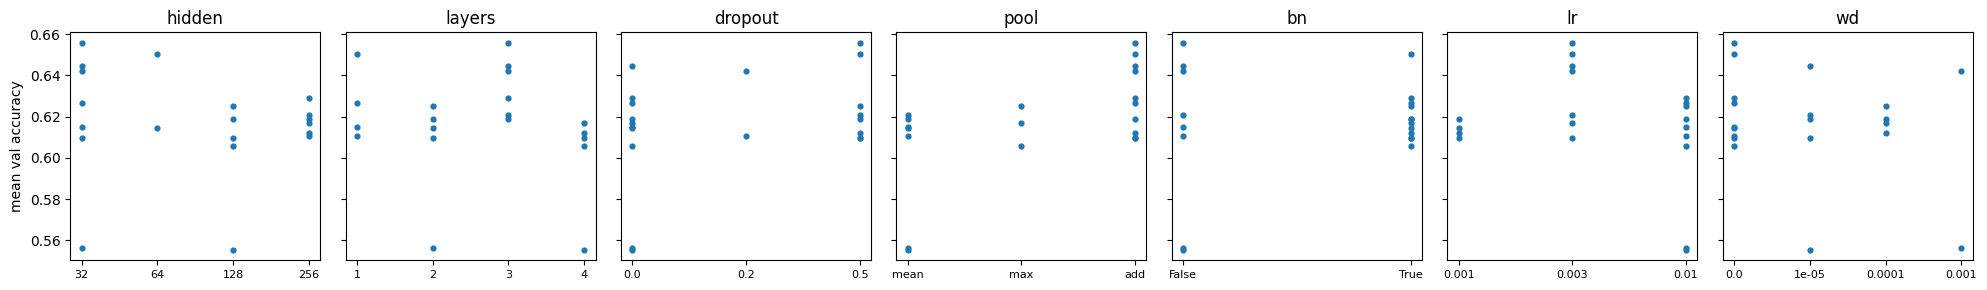

In [15]:
import matplotlib.pyplot as plt
search = search.sort_values('val', ascending=False)
print(search.head(10).round(4).to_string())
best = trials[search.index[0]]
print("\nbest:", best)
fig, ax = plt.subplots(1, len(space), figsize=(20, 3), sharey=True)
for a, k in zip(ax, space):
    a.scatter(search[k].map(space[k].index), search.val, s=12)
    a.set_xticks(range(len(space[k])), [str(v) for v in space[k]], fontsize=8)
    a.set_title(k)
ax[0].set_ylabel("mean val accuracy")
plt.tight_layout(); plt.savefig('gcn_search.png', dpi=150); plt.show()

## 16. Test the tuned GCN on ten fresh seeds

The search used other seeds. We retrain the chosen configuration on the ten final seeds and score each run once on the test graphs. The spread over seeds shows how much of any difference is noise.

In [16]:
runs = [fit(best, s) for s in final_seeds]
P = np.stack([predict(m, test_b) for m, _ in runs])
tuned = pd.DataFrame([scores(y_test, p) for p in P])
print(pd.DataFrame({'baseline': base.mean(), 'baseline std': base.std(), 'tuned': tuned.mean(), 'tuned std': tuned.std()}).round(4))

     baseline  baseline std   tuned  tuned std
acc    0.5530        0.0000  0.6028     0.0143
f1     0.3561        0.0000  0.5901     0.0219
auc    0.4968        0.0276  0.6325     0.0110


## 17. The model we analyse

The analyses that need a single model use the run with the highest validation accuracy among the ten. Picking the highest test accuracy instead would be peeking at the test set.

Its confusion matrix shows whether the errors fall mostly on one class.

seed 109   val acc = 0.6613   test: {'acc': 0.5853, 'f1': 0.5691, 'auc': 0.6276}


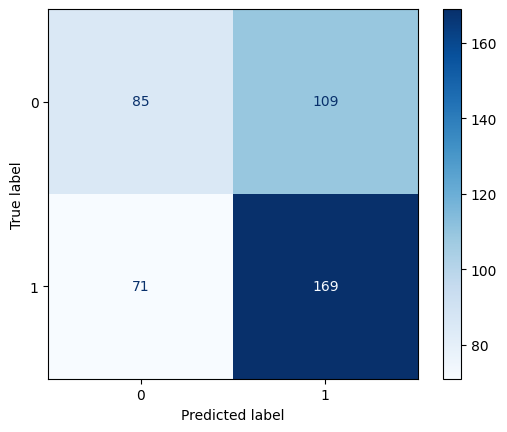

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
k = int(np.argmax([v for _, v in runs]))
model, p_best = runs[k][0], P[k]
print("seed", final_seeds[k], "  val acc =", round(runs[k][1], 4), "  test:", {m: round(float(v), 4) for m, v in scores(y_test, p_best).items()})
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best > .5)).plot(cmap='Blues')
plt.savefig('gcn_confusion.png', dpi=150); plt.show()

## 18. Ablation: does the GCN need both the features and the bonds?

An ablation removes one ingredient and retrains with the same tuned hyperparameters on the seeds in `abl_seeds`. Train, validation and test graphs are changed in the same way.

- **No edges ($\tilde A=I$).** Each atom sees only itself, so the GCN becomes a per-atom MLP followed by the readout. Only the bag of atoms is left.
- **Constant features.** Every $x_v$ becomes a vector of ones, so the model cannot tell atoms apart and only the shape of the molecule is left.

`Δ acc` is the change against the tuned GCN on the same seeds.

In [18]:
def no_edges(g): g.edge_index = g.edge_index[:, :0]; return g
def ones(g):     g.x = torch.ones_like(g.x); return g

def variant(f):
    return [f(g.clone()) for g in train_set], batches([f(g.clone()) for g in val_set]), batches([f(g.clone()) for g in test_set])

def run(c, tr, va, te):
    return pd.DataFrame([scores(y_test, predict(fit(c, s, tr, va)[0], te)) for s in abl_seeds])

def table(d):
    t = pd.DataFrame({k: v.mean() for k, v in d.items()}).T
    t['acc std'] = [v.acc.std() for v in d.values()]
    t['Δ acc'] = t.acc - t.acc.iloc[0]
    return t.round(4)

abl = {'tuned GCN': tuned.iloc[:len(abl_seeds)]}
for name, f in [('no edges (A = I)', no_edges), ('constant features', ones)]:
    abl[name] = run(best, *variant(f))
print(table(abl))

                      acc      f1     auc  acc std   Δ acc
tuned GCN          0.6088  0.6016  0.6397   0.0154  0.0000
no edges (A = I)   0.5926  0.5624  0.5808   0.0222 -0.0161
constant features  0.5696  0.5398  0.5752   0.0038 -0.0392


## 19. Depth and over-smoothing

Each GCN layer averages an atom with its neighbours. Repeated averaging pulls the embeddings of a connected graph towards the same vector, which is called over-smoothing, so accuracy should eventually fall as layers are added. The molecules are small, so a few layers already cover most of a graph.

We train the tuned configuration with 1, 2, 4 and 8 layers.

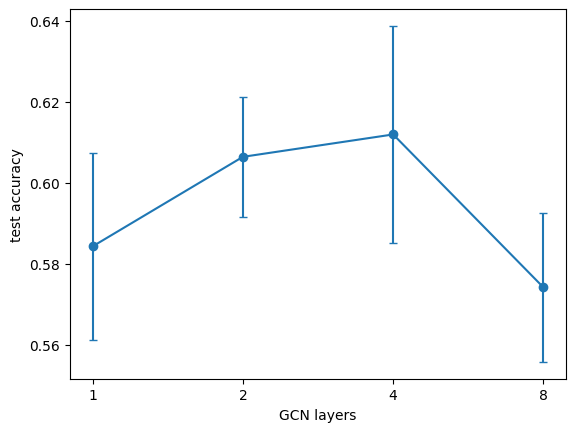

In [19]:
Ls = [1, 2, 4, 8]
depth = {L: run(dict(best, layers=L), train_set, val_b, test_b) for L in Ls}
plt.errorbar(Ls, [depth[L].acc.mean() for L in Ls], [depth[L].acc.std() for L in Ls], marker='o', capsize=3)
plt.xscale('log', base=2); plt.xticks(Ls, Ls)
plt.xlabel("GCN layers"); plt.ylabel("test accuracy")
plt.savefig('gcn_depth.png', dpi=150); plt.show()

## 20. Visualisation: t-SNE of graph embeddings

`embed` returns the vector the classifier sees, one per molecule. t-SNE maps these vectors to 2D while keeping near neighbours near.

On the left is the input itself, the mean of each molecule's raw atom features. On the right is the tuned GCN's embedding. Colour is the true class, and crosses are graphs the model gets wrong.

The silhouette score, computed in the original space and not in 2D, measures class separation on a scale from $-1$ to $1$.

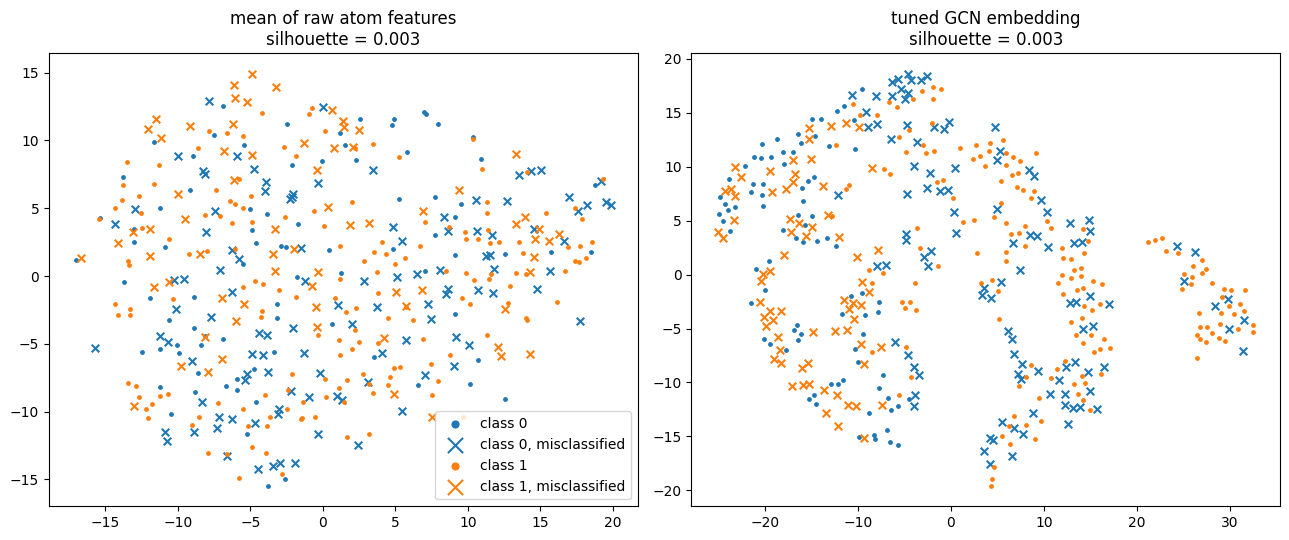

In [20]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

@torch.no_grad()
def embed_all(model, bs):
    model.eval()
    return torch.cat([model.embed(b.x, b.edge_index, b.batch) for b in bs]).cpu().numpy()

Z = {'mean of raw atom features': torch.cat([global_mean_pool(b.x, b.batch) for b in test_b]).cpu().numpy(),
     'tuned GCN embedding': embed_all(model, test_b)}
sil = {name: silhouette_score(E, y_test) for name, E in Z.items()}
wrong = (p_best > .5) != y_test
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (name, E) in zip(ax, Z.items()):
    T2 = TSNE(2, init='pca', random_state=0).fit_transform(E)
    for c, col in [(0, 'tab:blue'), (1, 'tab:orange')]:
        a.scatter(*T2[(y_test == c) & ~wrong].T, s=6, c=col, label=f'class {c}')
        a.scatter(*T2[(y_test == c) & wrong].T, s=30, c=col, marker='x', label=f'class {c}, misclassified')
    a.set_title(f"{name}\nsilhouette = {sil[name]:.3f}")
ax[0].legend(markerscale=2)
plt.tight_layout(); plt.savefig('gcn_tsne.png', dpi=150); plt.show()

## 21. Save the results

Everything needed to compare the GCN with the other models goes into one JSON file, together with the split indices. The per-run test probabilities are saved too, so the models' errors can later be compared graph by graph.

In [21]:
import json
res = dict(model='GCN', dataset='FRANKENSTEIN (TUDataset, 780 node attributes)',
           split=dict(rule='stratified 80/10/10, random_state=0', train=train_idx.tolist(), val=val_idx.tolist(), test=test_idx.tolist()),
           size_only_acc=size_acc, best_config=best,
           baseline=base.agg(['mean', 'std']).to_dict(), tuned=tuned.agg(['mean', 'std']).to_dict(), tuned_runs=tuned.to_dict('list'),
           ablation=table(abl).to_dict('index'),
           depth={f'layers={L}': [v.acc.mean(), v.acc.std()] for L, v in depth.items()},
           silhouette=sil, minutes=(time.time() - t0) / 60)
json.dump(res, open('gcn_frankenstein_results.json', 'w'), indent=1, default=float)
np.save('gcn_frankenstein_test_probs.npy', P)
search.to_csv('gcn_frankenstein_search.csv', index=False)
print("saved:", ', '.join(sorted(res)))
print(f"total run time: {res['minutes']:.0f} minutes")

saved: ablation, baseline, best_config, dataset, depth, minutes, model, silhouette, size_only_acc, split, tuned, tuned_runs
total run time: 52 minutes


## 22. Conclusion

The whole notebook ran in 52 minutes on a Kaggle T4.

**Results.** Always predicting the larger class gives 0.553 test accuracy, and the number of atoms alone gives 0.576. The textbook GCN never learns: on all ten seeds it predicts the larger class for every molecule (accuracy 0.553, ROC-AUC 0.497). The tuned GCN reaches 0.603 ± 0.014 accuracy, macro-F1 0.590 ± 0.022 and ROC-AUC 0.633 ± 0.011 over ten fresh seeds. The chosen configuration has 3 layers of width 32, sum readout, dropout 0.5, no batch norm, learning rate $3\cdot10^{-3}$ and no weight decay. FRANKENSTEIN is hard for a GCN: the tuned model is only five points above always guessing the larger class.

**Search.** The six best configurations all use the sum readout, and the top four all use learning rate $3\cdot10^{-3}$. A likely reason for the sum is that it keeps how many atoms of each kind a molecule has, which the mean and the max throw away. The two trials that failed to learn combine mean readout, no batch norm, learning rate $10^{-2}$ and at least two layers, the same recipe as the textbook baseline. The best validation accuracy (0.656) is well above the test accuracy (0.603): with 20 trials and only 434 validation graphs, the top trial is partly lucky.

**Errors.** The analysed run (seed 109, test accuracy 0.585) gets 169 of 240 class-1 molecules right (70%) but only 85 of 194 class-0 molecules (44%). It leans towards class 1, the larger class.

**What the GCN uses.** Removing the bonds ($\tilde A=I$) lowers accuracy by 0.016 to 0.593, about one standard deviation. Constant features lower it by 0.039 to 0.570, close to what size alone gives. So the GCN gets something from both, and more from the atom features than from the bonds.

**Depth.** Accuracy rises from 0.584 with 1 layer to 0.606 with 2 and 0.612 with 4, then falls to 0.574 with 8 layers, as over-smoothing predicts. The error bars overlap, so the trend is suggestive rather than certain.

**Visualisation.** The silhouette score is 0.003 for both the raw features and the GCN embedding. The GCN embedding forms visible clusters, but each cluster mixes both classes.

**Why so hard?** In the first layer the GCN averages each atom's pixel vector with its neighbours' before any non-linearity, so it sees a blend of several digit images rather than recognising each atom on its own first. A model that transforms each atom separately before mixing, such as GIN with its per-node MLP, may do better.